# Model Deployment Basics & Neural Network from Scratch
### Hack-o-Week | ArpitaBuilds

**Covers:**
- Model deployment basics: saving/loading trained models with `pickle` and `joblib`
- Perceptrons, activation functions, forward & backward propagation
- Loss functions and optimizers (SGD, Adam)
- A neural network built from scratch in NumPy: forward pass, loss, backprop, weight updates

**Dataset:** scikit-learn's built-in **Breast Cancer Wisconsin** dataset (real medical data, binary
classification, same one as earlier notebooks) plus the tiny AND / OR / XOR logic-gate datasets for
perceptron intuition. Nothing to download.

**Why this matters for your project:**
- Deployment: your stroke platform is a React + FastAPI app. The model has to be trained once, **saved
  to a file**, and loaded by the API at startup — that is exactly what `joblib`/`pickle` do.
- Neural nets from scratch: the chain rule and gradient descent from your Math-for-ML notebook finally
  become a working model. If you ever add a neural baseline next to XGBoost, you'll know what is
  happening inside it.


In [1]:
import os, time, pickle, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 5)
PINK, BLUE, GRAY, ORANGE = '#ff2d78', '#2d9dff', '#888888', '#f5a623'
print("Setup done ✅")

Setup done ✅


---
## 1. Model Deployment Basics: Saving & Loading Models

Training a model can take minutes or hours. You do **not** want your web app to retrain it every time
someone opens the page. The standard flow is:

1. **Train** the model once (in a notebook / script)
2. **Save** the trained object to a file (serialization)
3. **Load** that file inside your app (e.g. FastAPI) and call `.predict()` on new inputs

Two common tools for this in Python:
- **`pickle`** — Python's built-in serializer; works on almost any Python object
- **`joblib`** — built for scikit-learn-style objects; handles large NumPy arrays more efficiently and
  supports compression (this is what the scikit-learn docs recommend)

In [2]:
data = load_breast_cancer()
X_df = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, random_state=42, stratify=y)

# Always save the FULL pipeline (preprocessing + model) so the app can't forget a step
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=300, random_state=42))
])
pipe.fit(X_train_df, y_train)
print("Test accuracy before saving:", round(pipe.score(X_test_df, y_test), 4))

Test accuracy before saving: 0.9474


In [3]:
os.makedirs('saved_models', exist_ok=True)

# --- save with pickle ---
t0 = time.time()
with open('saved_models/model.pkl', 'wb') as f:
    pickle.dump(pipe, f)
pickle_save_time = time.time() - t0

# --- save with joblib (plain, and compressed) ---
t0 = time.time()
joblib.dump(pipe, 'saved_models/model.joblib')
joblib_save_time = time.time() - t0
joblib.dump(pipe, 'saved_models/model_compressed.joblib', compress=3)

for fname in ['model.pkl', 'model.joblib', 'model_compressed.joblib']:
    size_kb = os.path.getsize(f'saved_models/{fname}') / 1024
    print(f"{fname:28s} {size_kb:8.1f} KB")

model.pkl                       926.5 KB
model.joblib                    950.2 KB
model_compressed.joblib         188.4 KB


In [4]:
# --- load them back and confirm predictions are IDENTICAL to the original ---
with open('saved_models/model.pkl', 'rb') as f:
    loaded_pickle = pickle.load(f)
loaded_joblib = joblib.load('saved_models/model.joblib')

same_pickle = np.array_equal(pipe.predict(X_test_df), loaded_pickle.predict(X_test_df))
same_joblib = np.array_equal(pipe.predict(X_test_df), loaded_joblib.predict(X_test_df))
print("pickle round-trip gives identical predictions:", same_pickle)
print("joblib round-trip gives identical predictions:", same_joblib)

pickle round-trip gives identical predictions: True
joblib round-trip gives identical predictions: True


In [5]:
# --- what your FastAPI endpoint would effectively do: load ONCE, predict per request ---
MODEL = joblib.load('saved_models/model.joblib')     # done once at app startup

def predict_risk(patient: dict) -> float:
    row = pd.DataFrame([patient])                    # one patient -> one-row DataFrame
    return float(MODEL.predict_proba(row)[0, 1])     # probability of class 1

for i in range(3):
    patient = X_test_df.iloc[i].to_dict()
    print(f"patient {i}: predicted P(class 1 = benign) = {predict_risk(patient):.3f}   (true label: {y_test[i]})")

patient 0: predicted P(class 1 = benign) = 0.000   (true label: 0)
patient 1: predicted P(class 1 = benign) = 1.000   (true label: 1)
patient 2: predicted P(class 1 = benign) = 0.130   (true label: 0)


In [6]:
# XGBoost (your stroke model) also has its own native save format - portable across versions
import xgboost as xgb
xgb_model = xgb.XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train_df, y_train)

xgb_model.save_model('saved_models/xgb_model.json')

xgb_loaded = xgb.XGBClassifier()
xgb_loaded.load_model('saved_models/xgb_model.json')
print("XGBoost native save/load matches:",
      np.array_equal(xgb_model.predict(X_test_df), xgb_loaded.predict(X_test_df)))

# Record library versions next to the model file - a mismatch is the #1 reason loading breaks
print("\nsaved with -> scikit-learn", sklearn.__version__, "| python", sys.version.split()[0])

XGBoost native save/load matches: True

saved with -> scikit-learn 1.8.0 | python 3.12.3


**Deployment gotchas worth knowing (interviewers like these):**
1. **Never unpickle a file you don't trust.** `pickle.load` can execute arbitrary code hidden in the
   file. Only load model files you created or got from a trusted source.
2. **Version mismatch.** A model saved with one scikit-learn version may fail or behave differently
   when loaded with another. Pin versions in `requirements.txt` and note them with the model.
3. **Save the whole pipeline**, not just the final model — otherwise your app forgets to scale/impute.
4. **Load once at startup**, not inside the request handler — loading on every request makes the API
   slow.
5. **Pickling a custom class** only stores a *reference* to the class, so loading requires that class
   to be importable. We'll deal with this in section 8 by saving just the weights.

**Connects to your project:** wrap imputer + scaler + XGBoost in one `Pipeline`, `joblib.dump` it, and
let your FastAPI app load it once at startup. The React frontend then just sends patient values to a
`/predict` endpoint and gets a probability back.

A minimal FastAPI sketch of that idea (not executed here):
```python
from fastapi import FastAPI
import joblib, pandas as pd

app = FastAPI()
model = joblib.load("saved_models/model.joblib")      # loaded once

@app.post("/predict")
def predict(patient: dict):
    row = pd.DataFrame([patient])
    return {"risk": float(model.predict_proba(row)[0, 1])}
```

---
## 2. The Perceptron — a Single Artificial Neuron

A perceptron is the simplest neural network: **one neuron**.

`output = step( w1*x1 + w2*x2 + ... + b )`

It is just a dot product (from your linear algebra notebook) plus a bias, passed through a **step
function** (output 1 if the sum is above 0, else 0). Learning rule: for every wrong prediction, nudge
the weights toward the correct answer:

`w = w + lr * (target - prediction) * x`

Let's teach one to learn the logic gates AND, OR, and XOR.

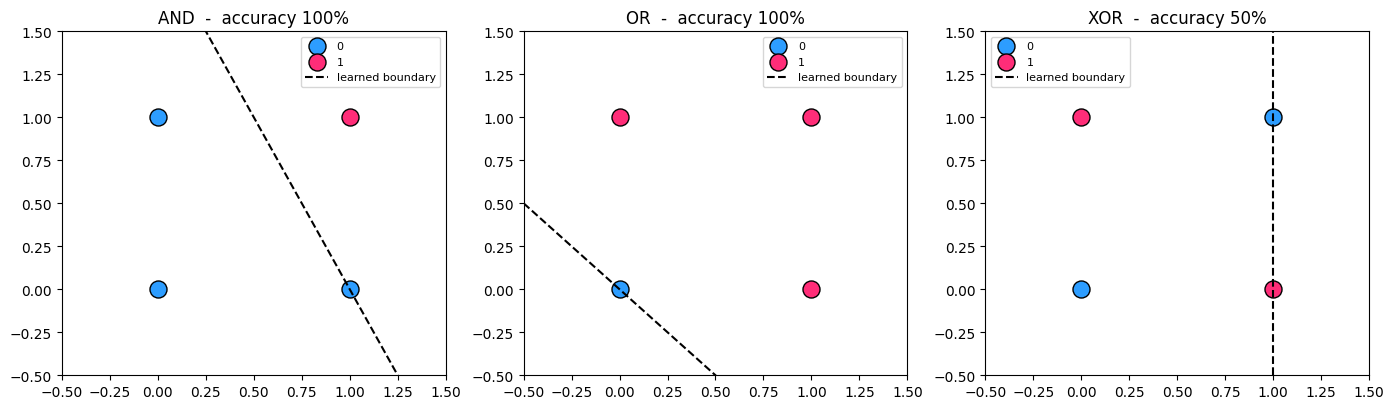

In [7]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=25):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        for _ in range(self.epochs):
            for xi, target in zip(X, y):
                pred = 1 if xi @ self.w + self.b > 0 else 0
                update = self.lr * (target - pred)
                self.w += update * xi
                self.b += update
        return self

    def predict(self, X):
        return (X @ self.w + self.b > 0).astype(int)

X_gate = np.array([[0,0],[0,1],[1,0],[1,1]])
gates = {'AND': np.array([0,0,0,1]),
         'OR':  np.array([0,1,1,1]),
         'XOR': np.array([0,1,1,0])}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (name, y_gate) in zip(axes, gates.items()):
    p = Perceptron().fit(X_gate, y_gate)
    acc = (p.predict(X_gate) == y_gate).mean()

    ax.scatter(X_gate[y_gate==0,0], X_gate[y_gate==0,1], color=BLUE, s=150, edgecolor='k', label='0')
    ax.scatter(X_gate[y_gate==1,0], X_gate[y_gate==1,1], color=PINK, s=150, edgecolor='k', label='1')
    xs = np.linspace(-0.5, 1.5, 50)
    if abs(p.w[1]) > 1e-9:
        ax.plot(xs, -(p.w[0]*xs + p.b)/p.w[1], 'k--', label='learned boundary')
    elif abs(p.w[0]) > 1e-9:                      # boundary is a vertical line x = -b/w0
        ax.axvline(-p.b / p.w[0], color='k', linestyle='--', label='learned boundary')
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_title(f"{name}  -  accuracy {acc*100:.0f}%")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Key takeaway:** a single perceptron draws **one straight line**. AND and OR can be separated by a
line, so it reaches 100%. XOR cannot — no single straight line puts (0,1) and (1,0) on one side and
(0,0) and (1,1) on the other, so the perceptron is stuck below 100% no matter how long it trains. In the XOR panel the best
it manages is a single line that gets 2 of the 4 points right (50%) - it keeps shifting the line to fix one
point and breaks another.

This famous limitation is exactly why we stack neurons into **layers** with non-linear activations —
we'll solve XOR with a small network in section 7.

---
## 3. Activation Functions

If every neuron only computed `w·x + b`, stacking layers would be pointless: a linear function of a
linear function is still just one linear function. **Activation functions add non-linearity**, which is
what lets networks learn curves, XOR, images, and everything else a straight line can't.

| Function | Formula | Output range | Used for |
|---|---|---|---|
| Sigmoid | 1 / (1 + e^-z) | (0, 1) | Output layer for binary classification (a probability) |
| Tanh | (e^z - e^-z) / (e^z + e^-z) | (-1, 1) | Hidden layers (older style), zero-centered |
| ReLU | max(0, z) | [0, inf) | Default for hidden layers in modern nets |
| Leaky ReLU | max(0.01z, z) | (-inf, inf) | ReLU variant that avoids "dead" neurons |

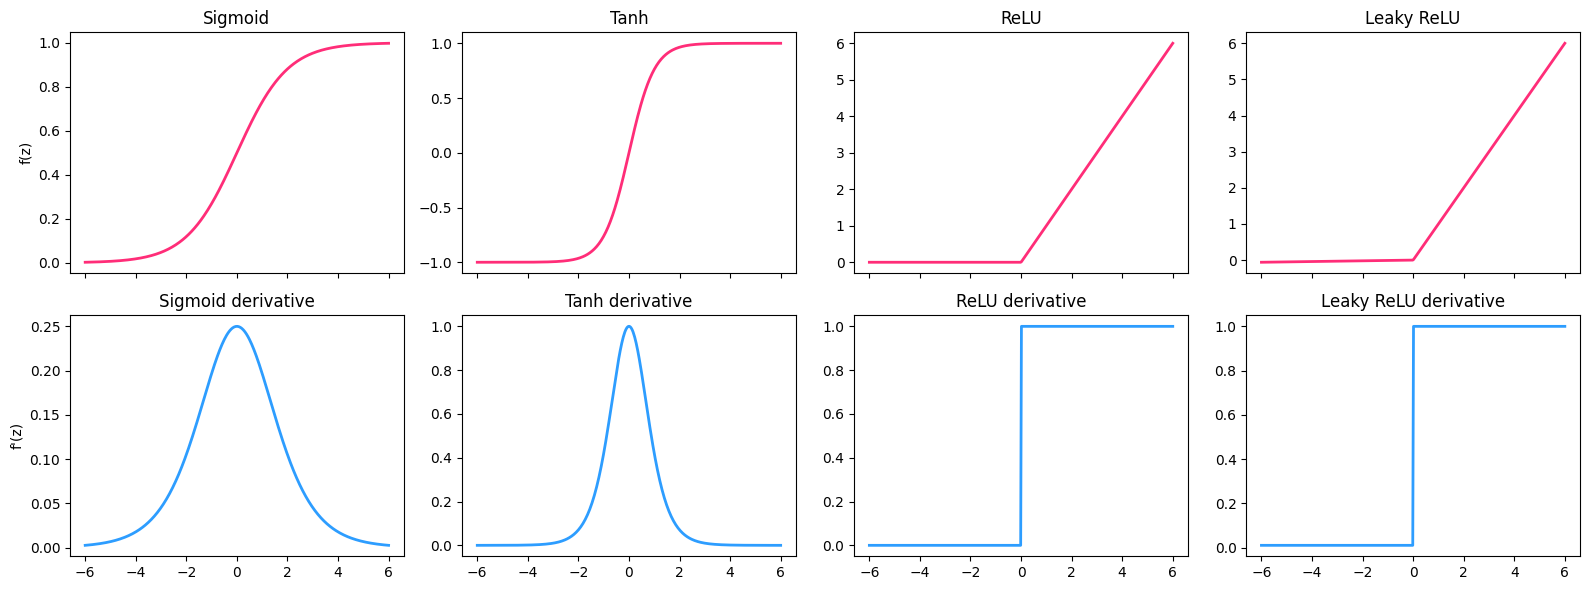

Max derivative of sigmoid: 0.25  (so gradients shrink at least 4x per sigmoid layer)
Derivative of ReLU for z>0: 1.0  (gradient passes through unchanged)


In [8]:
def sigmoid(z):   return 1 / (1 + np.exp(-z))
def tanh(z):      return np.tanh(z)
def relu(z):      return np.maximum(0, z)
def leaky_relu(z, a=0.01): return np.where(z > 0, z, a * z)

# derivatives (needed for backpropagation!)
def d_sigmoid(z): s = sigmoid(z); return s * (1 - s)
def d_tanh(z):    return 1 - np.tanh(z)**2
def d_relu(z):    return (z > 0).astype(float)
def d_leaky(z, a=0.01): return np.where(z > 0, 1.0, a)

z = np.linspace(-6, 6, 400)
funcs = [('Sigmoid', sigmoid, d_sigmoid), ('Tanh', tanh, d_tanh),
         ('ReLU', relu, d_relu), ('Leaky ReLU', leaky_relu, d_leaky)]

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for i, (name, f, df) in enumerate(funcs):
    axes[0, i].plot(z, f(z), color=PINK, linewidth=2)
    axes[0, i].set_title(name)
    axes[1, i].plot(z, df(z), color=BLUE, linewidth=2)
    axes[1, i].set_title(f"{name} derivative")
axes[0, 0].set_ylabel('f(z)'); axes[1, 0].set_ylabel("f'(z)")
plt.tight_layout()
plt.show()

print("Max derivative of sigmoid:", d_sigmoid(z).max().round(3), " (so gradients shrink at least 4x per sigmoid layer)")
print("Derivative of ReLU for z>0:", d_relu(np.array([2.0]))[0], " (gradient passes through unchanged)")

**Key takeaway:** the bottom row matters as much as the top. Backpropagation multiplies derivatives
layer after layer. Sigmoid's derivative never exceeds 0.25, so in deep networks the gradient shrinks
toward 0 as it travels backward — the **vanishing gradient** problem. ReLU's derivative is exactly 1 for
positive inputs, which is why it became the default for hidden layers. We'll use **ReLU in the hidden
layer and sigmoid at the output** (to get a probability).

---
## 4. Forward & Backward Propagation (one sample, by hand)

For a network with one hidden layer:

**Forward pass** (input → prediction → loss):
```
z1 = x  @ W1 + b1        a1 = relu(z1)
z2 = a1 @ W2 + b2        a2 = sigmoid(z2)         <- the prediction
loss = -[ y*log(a2) + (1-y)*log(1-a2) ]
```
**Backward pass** (loss → gradients, using the chain rule from your calculus notebook):
```
dz2 = a2 - y                       (sigmoid + cross-entropy simplify to this)
dW2 = a1.T @ dz2      db2 = dz2
da1 = dz2 @ W2.T
dz1 = da1 * relu'(z1)              (relu' is 1 where z1>0, else 0)
dW1 = x.T @ dz1       db1 = dz1
```
Every line is one link of the chain rule. Let's run it with small fixed numbers so you can see each
intermediate value.

In [9]:
x = np.array([[1.0, 2.0]])           # one sample, 2 features
y_true = np.array([[1.0]])            # true label

W1 = np.array([[0.5, -0.3],
               [0.2,  0.8]])
b1 = np.array([[0.1, -0.1]])
W2 = np.array([[0.7],
               [-0.5]])
b2 = np.array([[0.05]])

# ---------- FORWARD ----------
z1 = x @ W1 + b1
a1 = relu(z1)
z2 = a1 @ W2 + b2
a2 = sigmoid(z2)
loss = -(y_true*np.log(a2) + (1-y_true)*np.log(1-a2))

print("z1 =", z1.round(3), " a1 =", a1.round(3))
print("z2 =", z2.round(3), " a2 (prediction) =", a2.round(3))
print("loss =", loss.round(4))

# ---------- BACKWARD ----------
dz2 = a2 - y_true
dW2 = a1.T @ dz2
db2 = dz2
da1 = dz2 @ W2.T
dz1 = da1 * d_relu(z1)
dW1 = x.T @ dz1
db1 = dz1

print("\ndz2 =", dz2.round(4))
print("dW2 =\n", dW2.round(4))
print("dW1 =\n", dW1.round(4))

z1 = [[1.  1.2]]  a1 = [[1.  1.2]]
z2 = [[0.15]]  a2 (prediction) = [[0.537]]
loss = [[0.621]]

dz2 = [[-0.4626]]
dW2 =
 [[-0.4626]
 [-0.5551]]
dW1 =
 [[-0.3238  0.2313]
 [-0.6476  0.4626]]


In [10]:
# PROOF it is right: compare against a numerical derivative (nudge one weight, watch the loss move)
def forward_loss(W1_, W2_):
    a1_ = relu(x @ W1_ + b1)
    a2_ = sigmoid(a1_ @ W2_ + b2)
    return (-(y_true*np.log(a2_) + (1-y_true)*np.log(1-a2_))).item()

eps = 1e-6
W1_plus  = W1.copy(); W1_plus[0, 0]  += eps
W1_minus = W1.copy(); W1_minus[0, 0] -= eps
numeric = (forward_loss(W1_plus, W2) - forward_loss(W1_minus, W2)) / (2 * eps)

print("Backprop gradient  dL/dW1[0,0] =", round(float(dW1[0, 0]), 8))
print("Numerical gradient dL/dW1[0,0] =", round(numeric, 8))

Backprop gradient  dL/dW1[0,0] = -0.32379911
Numerical gradient dL/dW1[0,0] = -0.32379911


**Key takeaway:** the two numbers match. That "nudge the weight and watch the loss" check is called
**gradient checking** — it is how people verify a hand-written backprop is correct, and we'll reuse it
on the full network below.

---
## 5. Loss Functions

The loss function turns "how wrong is the model?" into **one number** that training tries to minimize.

- **MSE (Mean Squared Error)** = mean of (prediction - truth)². Standard for **regression**.
- **Binary Cross-Entropy (BCE / log loss)** = -[ y·log(p) + (1-y)·log(1-p) ]. Standard for
  **binary classification** (your stroke / no-stroke problem).

BCE punishes a *confident wrong* answer extremely harshly: predicting p=0.01 when the truth is 1 costs
log(100) ≈ 4.6, while MSE would cost at most 1.

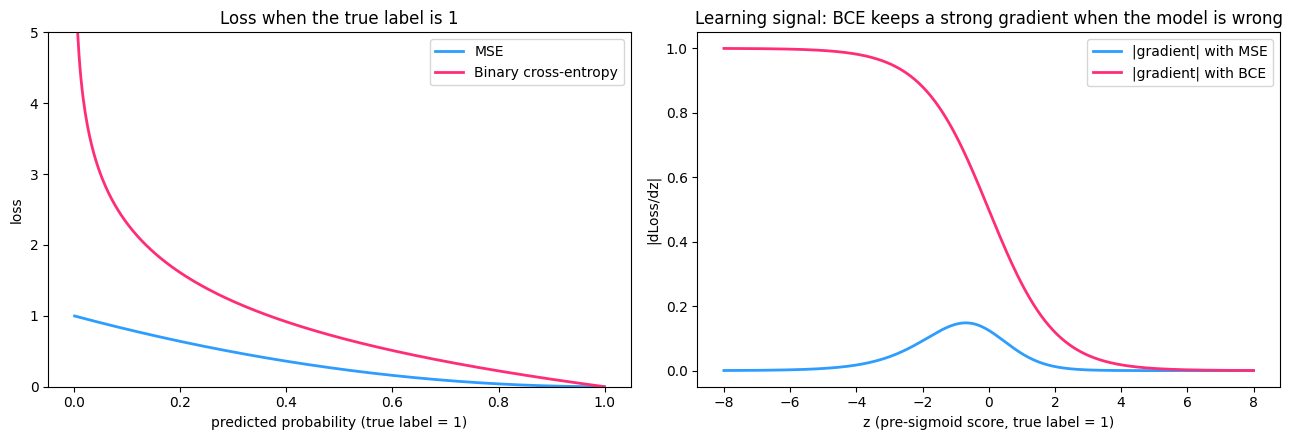

In [11]:
p = np.linspace(0.001, 0.999, 500)     # predicted probability, true label y = 1

mse_loss = (1 - p)**2
bce_loss = -np.log(p)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(p, mse_loss, color=BLUE, linewidth=2, label='MSE')
axes[0].plot(p, bce_loss, color=PINK, linewidth=2, label='Binary cross-entropy')
axes[0].set_ylim(0, 5)
axes[0].set_xlabel('predicted probability (true label = 1)'); axes[0].set_ylabel('loss')
axes[0].set_title("Loss when the true label is 1"); axes[0].legend()

# gradient w.r.t. the pre-sigmoid value z - this is what actually drives learning
z_vals = np.linspace(-8, 8, 400)
a = sigmoid(z_vals)
grad_mse = (a - 1) * a * (1 - a)       # d/dz of 0.5*(a-1)^2
grad_bce = (a - 1)                     # d/dz of -log(a)
axes[1].plot(z_vals, np.abs(grad_mse), color=BLUE, linewidth=2, label='|gradient| with MSE')
axes[1].plot(z_vals, np.abs(grad_bce), color=PINK, linewidth=2, label='|gradient| with BCE')
axes[1].set_xlabel('z (pre-sigmoid score, true label = 1)'); axes[1].set_ylabel('|dLoss/dz|')
axes[1].set_title("Learning signal: BCE keeps a strong gradient when the model is wrong"); axes[1].legend()

plt.tight_layout()
plt.show()

**Key takeaway:** look at the right plot at z = -6 (the model is confidently **wrong**). With MSE
the gradient is almost 0, so the model barely learns from its worst mistakes. With BCE the gradient
stays large, so it corrects itself quickly. That is why classification uses cross-entropy, and why the
backprop above simplified so nicely to `dz2 = a2 - y`.

---
## 6. Optimizers: SGD and Adam

Once backprop gives gradients, the **optimizer** decides how to use them to update the weights.

- **SGD (Stochastic Gradient Descent):** `w = w - lr * gradient`. Computed on a small random
  *mini-batch* instead of the whole dataset, which is faster and adds helpful noise. Simple, but one
  learning rate for every weight, and it zigzags on awkward loss surfaces.
- **Adam:** keeps a running average of the gradient (**momentum**, `m`) *and* of the squared gradient
  (`v`), then scales each weight's step individually:
  `w = w - lr * m_hat / (sqrt(v_hat) + eps)`.
  Weights with consistently large gradients take smaller steps; weights with small gradients take
  bigger ones. It is the usual default in deep learning.

Let's race them on a deliberately awkward loss surface: a long narrow valley,
`f(x, y) = 0.5*x² + 12.5*y²` (steep in y, shallow in x).

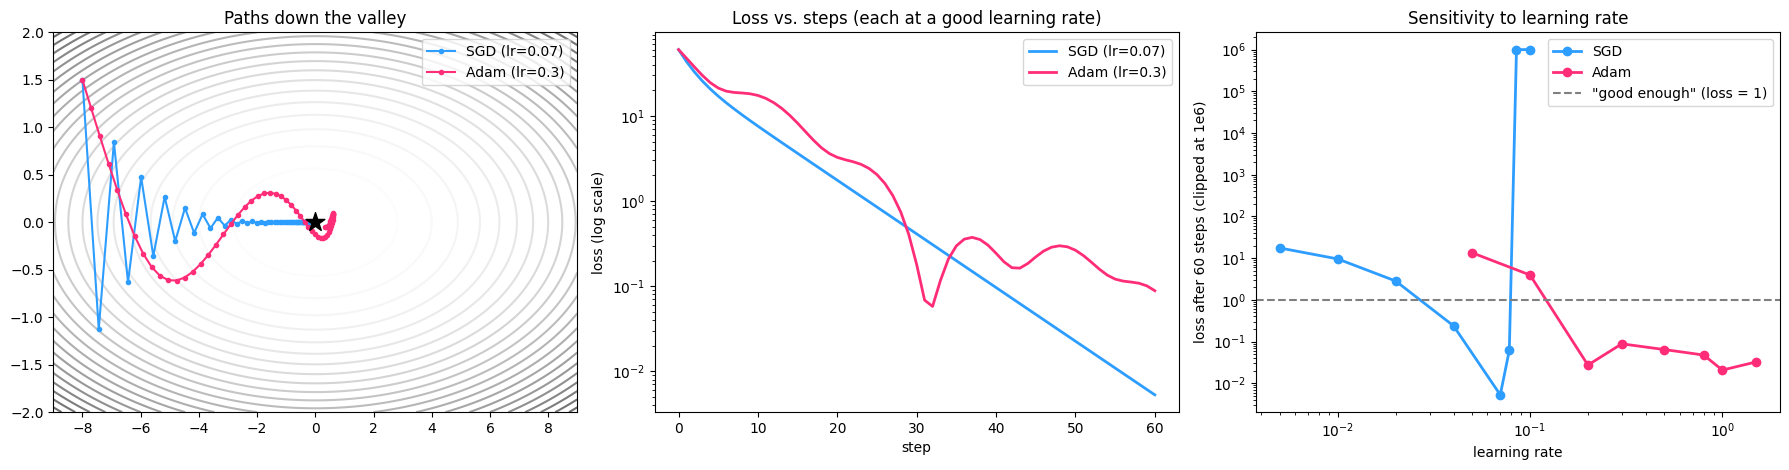

Steps to reach loss < 0.1  ->  SGD (lr=0.07): 40   Adam (lr=0.3): 31
Learning rates tried that reach loss < 1 within 60 steps  ->  SGD: 3 of 8   Adam: 6 of 8
SGD loss at lr=0.085 and 0.1 (just above its stability limit): 1.0e+06 1.0e+06


In [12]:
def f(p):      return 0.5 * p[0]**2 + 12.5 * p[1]**2
def grad(p):   return np.array([p[0], 25.0 * p[1]])

def run_sgd(start, lr=0.07, steps=60):
    p = np.array(start, float); path = [p.copy()]
    for _ in range(steps):
        p = p - lr * grad(p)
        path.append(p.copy())
    return np.array(path)

def run_adam(start, lr=0.3, steps=60, b1=0.9, b2=0.999, eps=1e-8):
    p = np.array(start, float); path = [p.copy()]
    m = np.zeros_like(p); v = np.zeros_like(p)
    for t in range(1, steps + 1):
        g = grad(p)
        m = b1 * m + (1 - b1) * g                 # momentum (average gradient)
        v = b2 * v + (1 - b2) * g**2              # average squared gradient
        m_hat = m / (1 - b1**t)                   # bias correction (matters early on)
        v_hat = v / (1 - b2**t)
        p = p - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(p.copy())
    return np.array(path)

start = [-8.0, 1.5]
sgd_path  = run_sgd(start, lr=0.07)      # SGD at its best: just under its stability limit (2/25 = 0.08)
adam_path = run_adam(start, lr=0.3)

xs = np.linspace(-9, 9, 200); ys = np.linspace(-2, 2, 200)
XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * XX**2 + 12.5 * YY**2

# how sensitive is each optimizer to the learning rate? (loss after 60 steps, clipped for plotting)
sgd_lrs  = np.array([0.005, 0.01, 0.02, 0.04, 0.07, 0.078, 0.085, 0.1])
adam_lrs = np.array([0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 1.5])
def final_loss(path):
    val = f(path[-1])
    return min(val, 1e6) if np.isfinite(val) else 1e6
sgd_final  = [final_loss(run_sgd(start, lr))  for lr in sgd_lrs]
adam_final = [final_loss(run_adam(start, lr)) for lr in adam_lrs]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].contour(XX, YY, ZZ, levels=25, cmap='Greys', alpha=0.6)
axes[0].plot(sgd_path[:,0],  sgd_path[:,1],  'o-', color=BLUE, markersize=3, label='SGD (lr=0.07)')
axes[0].plot(adam_path[:,0], adam_path[:,1], 'o-', color=PINK, markersize=3, label='Adam (lr=0.3)')
axes[0].scatter([0], [0], color='black', marker='*', s=200, zorder=5)
axes[0].set_title("Paths down the valley"); axes[0].legend()

axes[1].plot([f(p) for p in sgd_path],  color=BLUE, linewidth=2, label='SGD (lr=0.07)')
axes[1].plot([f(p) for p in adam_path], color=PINK, linewidth=2, label='Adam (lr=0.3)')
axes[1].set_yscale('log'); axes[1].set_xlabel('step'); axes[1].set_ylabel('loss (log scale)')
axes[1].set_title("Loss vs. steps (each at a good learning rate)"); axes[1].legend()

axes[2].plot(sgd_lrs,  sgd_final,  'o-', color=BLUE, linewidth=2, label='SGD')
axes[2].plot(adam_lrs, adam_final, 'o-', color=PINK, linewidth=2, label='Adam')
axes[2].axhline(1, color='gray', linestyle='--', label='"good enough" (loss = 1)')
axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_xlabel('learning rate'); axes[2].set_ylabel('loss after 60 steps (clipped at 1e6)')
axes[2].set_title("Sensitivity to learning rate"); axes[2].legend()
plt.tight_layout()
plt.show()

def steps_to(path, thr=0.1):
    for i, q in enumerate(path):
        if f(q) < thr: return i
    return None

print("Steps to reach loss < 0.1  ->  SGD (lr=0.07):", steps_to(run_sgd(start, 0.07, 120)),
      "  Adam (lr=0.3):", steps_to(run_adam(start, 0.3, 120)))
print("Learning rates tried that reach loss < 1 within 60 steps  ->  SGD:",
      sum(l < 1 for l in sgd_final), "of", len(sgd_lrs), "  Adam:", sum(l < 1 for l in adam_final), "of", len(adam_lrs))
print("SGD loss at lr=0.085 and 0.1 (just above its stability limit):", f"{sgd_final[6]:.1e}", f"{sgd_final[7]:.1e}")

**Key takeaway (read the three plots together):**
- Left/middle: with a *well-tuned* learning rate, plain SGD and Adam both get near the minimum in a
  similar number of steps (Adam first dips below loss 0.1 a bit sooner). A good SGD is not "bad" - on a
  simple problem it can match Adam. Notice, though, that Adam's path *overshoots and rings around* the
  minimum at a constant learning rate (its momentum carries it past), so its loss bounces back up after
  the first dip. This is why Adam is often paired with learning-rate decay.
- Right plot is the real difference: SGD only works inside a **narrow window** of learning rates. Too
  small and it crawls; just above ~0.08 (set by the steep y-direction) it **diverges** and the loss
  explodes. Adam reaches a low loss across a **much wider range** of learning rates, because it rescales
  each weight's step by its own gradient history.
- In real networks there are thousands to millions of weights with very different gradient sizes, so
  one SGD learning rate rarely suits all of them. That robustness (less tuning pain) is the main reason
  Adam is the usual default, while carefully tuned SGD (often with momentum) is still used when people
  want the best final generalization.

**Rule of thumb for learning rates:** SGD often needs ~0.01-0.1; Adam usually works with ~0.001-0.01.
Same model, very different "good" learning rates.

---
## 7. A Neural Network from Scratch (NumPy only)

Now we assemble everything: **forward pass → loss → backward pass → optimizer update**, wrapped in a
small class. Architecture: `input → hidden layer (ReLU) → output (sigmoid)`.

Training loop for each epoch:
1. Shuffle the data and split it into mini-batches
2. For each batch: forward pass, backward pass, update weights (SGD or Adam)
3. Record the loss so we can plot the learning curve

In [13]:
class SimpleNN:
    def __init__(self, n_in, n_hidden, lr=0.01, optimizer='sgd', seed=42):
        rng = np.random.default_rng(seed)
        self.params = {
            'W1': rng.normal(0, np.sqrt(2 / n_in),     (n_in, n_hidden)),   # He initialization (for ReLU)
            'b1': np.zeros((1, n_hidden)),
            'W2': rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, 1)),
            'b2': np.zeros((1, 1)),
        }
        self.lr = lr
        self.optimizer = optimizer
        # Adam's running averages (unused for SGD)
        self.m = {k: np.zeros_like(v) for k, v in self.params.items()}
        self.v = {k: np.zeros_like(v) for k, v in self.params.items()}
        self.t = 0
        self.loss_history = []

    # ---------- forward ----------
    def forward(self, X):
        p = self.params
        z1 = X @ p['W1'] + p['b1']
        a1 = np.maximum(0, z1)                       # ReLU
        z2 = a1 @ p['W2'] + p['b2']
        a2 = 1 / (1 + np.exp(-z2))                   # sigmoid
        return a2, (X, z1, a1, a2)

    # ---------- loss ----------
    @staticmethod
    def bce_loss(a2, y):
        a2 = np.clip(a2, 1e-12, 1 - 1e-12)           # avoid log(0)
        return float(-np.mean(y * np.log(a2) + (1 - y) * np.log(1 - a2)))

    # ---------- backward ----------
    def backward(self, cache, y):
        X, z1, a1, a2 = cache
        m = X.shape[0]
        dz2 = (a2 - y) / m                           # averaged over the batch
        dW2 = a1.T @ dz2
        db2 = dz2.sum(axis=0, keepdims=True)
        da1 = dz2 @ self.params['W2'].T
        dz1 = da1 * (z1 > 0)                         # ReLU derivative
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0, keepdims=True)
        return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

    # ---------- weight update ----------
    def update(self, grads, b1=0.9, b2=0.999, eps=1e-8):
        if self.optimizer == 'sgd':
            for k in self.params:
                self.params[k] -= self.lr * grads[k]
        elif self.optimizer == 'adam':
            self.t += 1
            for k in self.params:
                self.m[k] = b1 * self.m[k] + (1 - b1) * grads[k]
                self.v[k] = b2 * self.v[k] + (1 - b2) * grads[k]**2
                m_hat = self.m[k] / (1 - b1**self.t)
                v_hat = self.v[k] / (1 - b2**self.t)
                self.params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + eps)

    # ---------- training loop ----------
    def fit(self, X, y, epochs=100, batch_size=32, seed=0):
        y = y.reshape(-1, 1)
        rng = np.random.default_rng(seed)
        n = X.shape[0]
        for epoch in range(epochs):
            order = rng.permutation(n)
            for start in range(0, n, batch_size):
                idx = order[start:start + batch_size]
                a2, cache = self.forward(X[idx])
                grads = self.backward(cache, y[idx])
                self.update(grads)
            full_pred, _ = self.forward(X)
            self.loss_history.append(self.bce_loss(full_pred, y))
        return self

    def predict_proba(self, X):
        return self.forward(X)[0].ravel()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

print("SimpleNN defined. Lines of real logic: forward, loss, backward, update, fit.")

SimpleNN defined. Lines of real logic: forward, loss, backward, update, fit.


In [14]:
# ---- GRADIENT CHECK on the full class (sanity test before trusting it) ----
rng = np.random.default_rng(1)
X_chk = rng.normal(size=(8, 5))
y_chk = rng.integers(0, 2, size=(8, 1)).astype(float)

net = SimpleNN(n_in=5, n_hidden=4, seed=3)
a2, cache = net.forward(X_chk)
analytic = net.backward(cache, y_chk)

def loss_at(net, X, y):
    return net.bce_loss(net.forward(X)[0], y)

eps = 1e-5
print(f"{'parameter':>12s} {'backprop':>14s} {'numerical':>14s} {'rel. diff':>12s}")
for name, idx in [('W1', (0, 0)), ('W1', (3, 2)), ('b1', (0, 1)), ('W2', (1, 0)), ('b2', (0, 0))]:
    orig = net.params[name][idx]
    net.params[name][idx] = orig + eps; lp = loss_at(net, X_chk, y_chk)
    net.params[name][idx] = orig - eps; lm = loss_at(net, X_chk, y_chk)
    net.params[name][idx] = orig
    numeric = (lp - lm) / (2 * eps)
    a = analytic[name][idx]
    rel = abs(a - numeric) / max(1e-12, abs(a) + abs(numeric))
    print(f"{name + str(idx):>12s} {a:14.8f} {numeric:14.8f} {rel:12.2e}")
print("\nRelative differences around 1e-7 or smaller mean the backprop code is correct.")

   parameter       backprop      numerical    rel. diff
    W1(0, 0)     0.00097802     0.00097802     1.21e-09
    W1(3, 2)     0.08849630     0.08849630     9.69e-12
    b1(0, 1)     0.02362406     0.02362406     1.89e-11
    W2(1, 0)     0.17761333     0.17761333     1.97e-11
    b2(0, 0)     0.04362570     0.04362570     4.32e-11

Relative differences around 1e-7 or smaller mean the backprop code is correct.


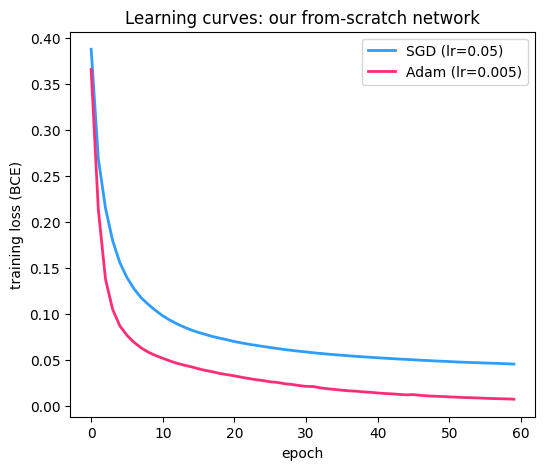

model                         test acc  test AUC
From-scratch NN (SGD)            0.965     0.994
From-scratch NN (Adam)           0.956     0.994
sklearn LogisticRegression       0.982     0.995


In [15]:
# ---- Train on the Breast Cancer data, comparing SGD vs Adam ----
scaler = StandardScaler().fit(X_train_df)          # fit on TRAIN only (no leakage)
Xtr = scaler.transform(X_train_df)
Xte = scaler.transform(X_test_df)

nn_sgd  = SimpleNN(n_in=30, n_hidden=16, lr=0.05,  optimizer='sgd').fit(Xtr, y_train, epochs=60, batch_size=32)
nn_adam = SimpleNN(n_in=30, n_hidden=16, lr=0.005, optimizer='adam').fit(Xtr, y_train, epochs=60, batch_size=32)

plt.plot(nn_sgd.loss_history,  color=BLUE, linewidth=2, label='SGD (lr=0.05)')
plt.plot(nn_adam.loss_history, color=PINK, linewidth=2, label='Adam (lr=0.005)')
plt.xlabel('epoch'); plt.ylabel('training loss (BCE)')
plt.title("Learning curves: our from-scratch network")
plt.legend()
plt.show()

baseline = LogisticRegression(max_iter=5000).fit(Xtr, y_train)
print(f"{'model':28s} {'test acc':>9s} {'test AUC':>9s}")
for name, model in [('From-scratch NN (SGD)', nn_sgd), ('From-scratch NN (Adam)', nn_adam)]:
    print(f"{name:28s} {(model.predict(Xte) == y_test).mean():9.3f} {roc_auc_score(y_test, model.predict_proba(Xte)):9.3f}")
print(f"{'sklearn LogisticRegression':28s} {baseline.score(Xte, y_test):9.3f} {roc_auc_score(y_test, baseline.predict_proba(Xte)[:,1]):9.3f}")

**Key takeaway:** a network written in about 60 lines of NumPy reaches the same ballpark accuracy as
scikit-learn's Logistic Regression on this data — because this dataset is nearly linearly separable.
The point of the exercise is not to beat sklearn, it is that **you now know every step**: forward
pass, BCE loss, backprop through the chain rule, and an SGD/Adam update. On harder, non-linear data the
hidden layer is what makes the difference — we prove that next with XOR.

Predicted probabilities: [0. 1. 1. 0.]
Predicted classes:       [0 1 1 0]
True classes:            [0 1 1 0]
XOR accuracy: 100.0 %   (single perceptron was stuck below 100%)


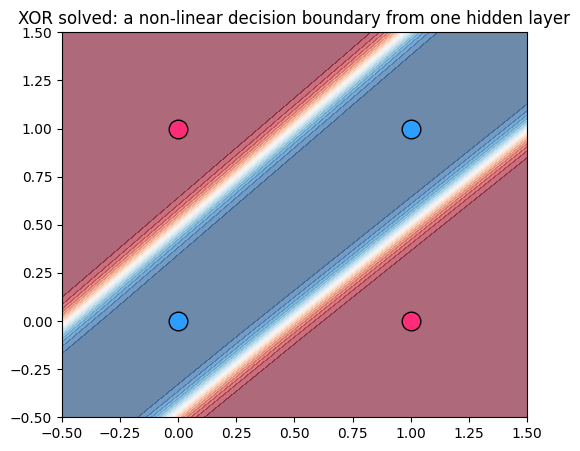

In [16]:
# ---- The hidden layer solves XOR - the problem a single perceptron could not ----
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

xor_net = SimpleNN(n_in=2, n_hidden=8, lr=0.05, optimizer='adam', seed=0)
xor_net.fit(X_xor, y_xor, epochs=1500, batch_size=4)

print("Predicted probabilities:", xor_net.predict_proba(X_xor).round(3))
print("Predicted classes:      ", xor_net.predict(X_xor))
print("True classes:           ", y_xor)
print("XOR accuracy:", (xor_net.predict(X_xor) == y_xor).mean() * 100, "%   (single perceptron was stuck below 100%)")

# decision regions: the hidden layer bends the boundary
gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid = np.c_[gx.ravel(), gy.ravel()]
zz = xor_net.predict_proba(grid).reshape(gx.shape)
plt.contourf(gx, gy, zz, levels=20, cmap='RdBu_r', alpha=0.6)
plt.scatter(X_xor[y_xor==0,0], X_xor[y_xor==0,1], color=BLUE, s=180, edgecolor='k')
plt.scatter(X_xor[y_xor==1,0], X_xor[y_xor==1,1], color=PINK, s=180, edgecolor='k')
plt.title("XOR solved: a non-linear decision boundary from one hidden layer")
plt.show()

---
## 8. Deploying the From-Scratch Model (tying sections 1 and 7 together)

Earlier we noted that pickling a **custom class** stores only a reference to it. If you pickle a
`SimpleNN` object from a notebook and try to load it in a different script (like your FastAPI app)
where `SimpleNN` isn't defined, loading fails.

The robust approach: **save just the learned numbers** (weights + the scaler's statistics), and rebuild
the model from them at load time.

In [17]:
# Save only the weights + scaler (plain dicts/arrays - no custom classes involved)
artifact = {
    'params': nn_adam.params,
    'scaler': scaler,                 # sklearn object - fine to pickle, the library is importable
    'feature_names': list(X_train_df.columns),
    'n_hidden': 16,
}
joblib.dump(artifact, 'saved_models/scratch_nn.joblib')
np.savez('saved_models/scratch_nn_weights.npz', **nn_adam.params)   # NumPy-native alternative
print("Saved. File size:", round(os.path.getsize('saved_models/scratch_nn.joblib') / 1024, 1), "KB")

# ---- later / in another process: rebuild and predict ----
loaded = joblib.load('saved_models/scratch_nn.joblib')
restored = SimpleNN(n_in=30, n_hidden=loaded['n_hidden'])
restored.params = loaded['params']

X_new = loaded['scaler'].transform(X_test_df)
same = np.allclose(restored.predict_proba(X_new), nn_adam.predict_proba(Xte))
print("Restored network gives identical probabilities:", same)

Saved. File size: 6.9 KB
Restored network gives identical probabilities: True
